# 01. Data Understanding — Household Purchase Behavior

Phân tích hành vi mua lại theo 5 nhóm tần suất (Dunnhumby, 2 năm).

| Nhóm | Range | Ý nghĩa |
|------|-------|----------|
| Mua ít | 1–12 | < 1 lần/tháng |
| Thỉnh thoảng | 13–39 | ~1–2 lần/tháng |
| Hàng tháng | 40–79 | ~2–4 lần/tháng |
| Hàng tuần | 80–149 | ~1–2 lần/tuần |
| Thường xuyên | 150+ | > 2 lần/tuần |

## Setup

In [70]:
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

_spec = importlib.util.spec_from_file_location(
    'plot_household_baskets', ROOT / 'scripts' / 'plot_household_baskets.py'
)
_mod = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(_mod)

load_hh_metrics              = _mod.load_hh_metrics
plot_purchase_frequency      = _mod.plot_purchase_frequency
plot_spending_by_frequency   = _mod.plot_spending_by_frequency
plot_baskets_per_hh          = _mod.plot_baskets_per_hh
plot_active_days             = _mod.plot_active_days
plot_purchase_rate_weekly    = _mod.plot_purchase_rate_weekly
plot_purchase_rate_monthly   = _mod.plot_purchase_rate_monthly
summary_table                = _mod.summary_table

DATA   = ROOT / 'data' / 'raw' / 'Dunnhumby' / 'transaction_data.csv'
CHARTS = ROOT / 'output' / 'charts'

## 1. Load

In [71]:
hh = load_hh_metrics(DATA)
display(hh[['purchase_count', 'active_days', 'rate_weekly', 'rate_monthly', 'total_spending']]
        .describe(percentiles=[.1, .25, .5, .75, .9, .95]).round(1))

,purchase_count,active_days,rate_weekly,rate_monthly,total_spending
count,2500.0,2500.0,2500.0,2500.0,2500.0
mean,110.6,90.2,1.1,4.7,3223.0
std,115.7,76.3,1.1,4.9,3349.0
min,1.0,1.0,0.0,0.0,8.2
10%,18.0,17.0,0.2,0.8,389.9
25%,39.0,34.0,0.4,1.6,970.7
50%,79.0,70.0,0.8,3.3,2157.8
75%,142.2,124.0,1.4,6.0,4413.3
90%,229.1,189.0,2.3,9.7,7448.2
95%,321.0,245.0,3.2,13.5,9754.1


## 2. % Household theo nhóm

In [72]:
plot_purchase_frequency(hh, CHARTS / 'chart1_pct_household.png')

  ✔  Saved: v:\Propensity_VSF\output\charts\chart1_pct_household.png


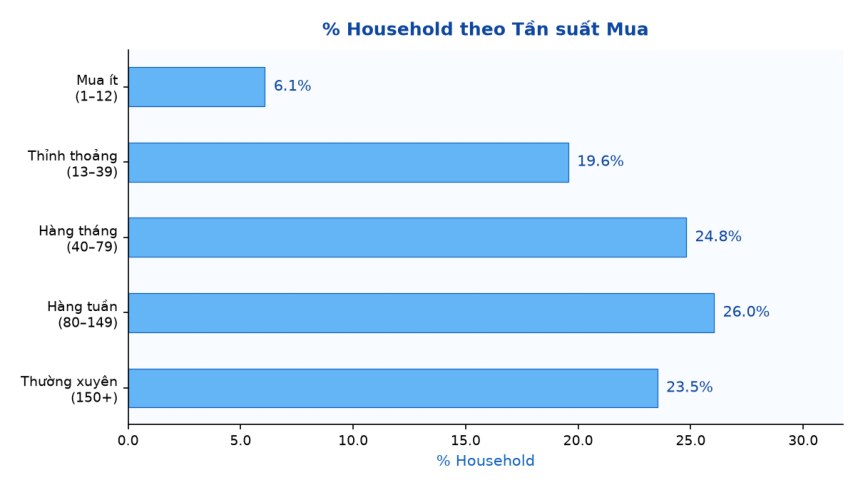

In [73]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg

def show(path): 
    fig, ax = plt.subplots(figsize=(9, 5)); ax.imshow(mpimg.imread(str(path))); ax.axis('off'); plt.tight_layout(); plt.show()

show(CHARTS / 'chart1_pct_household.png')

## 3. % Spending theo nhóm

  ✔  Saved: v:\Propensity_VSF\output\charts\chart2_pct_spending.png


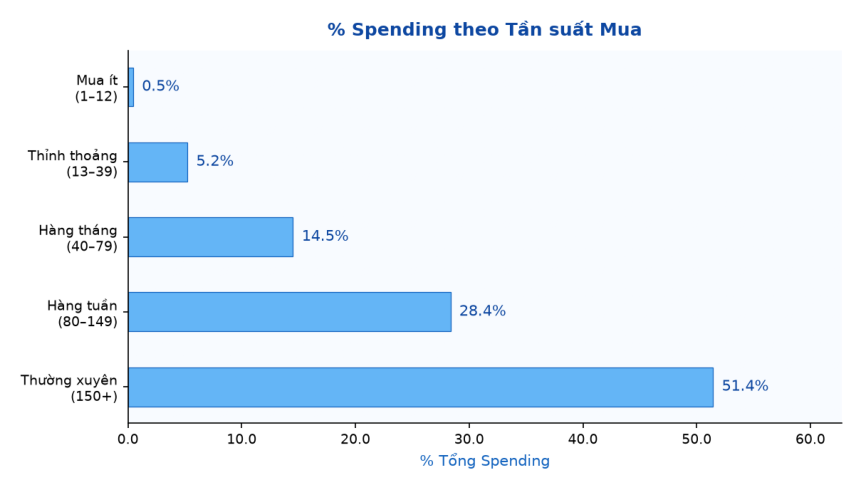

In [74]:
plot_spending_by_frequency(hh, CHARTS / 'chart2_pct_spending.png')
show(CHARTS / 'chart2_pct_spending.png')

## 4. TB Basket / Household theo nhóm

  ✔  Saved: v:\Propensity_VSF\output\charts\chart3_baskets_per_hh.png


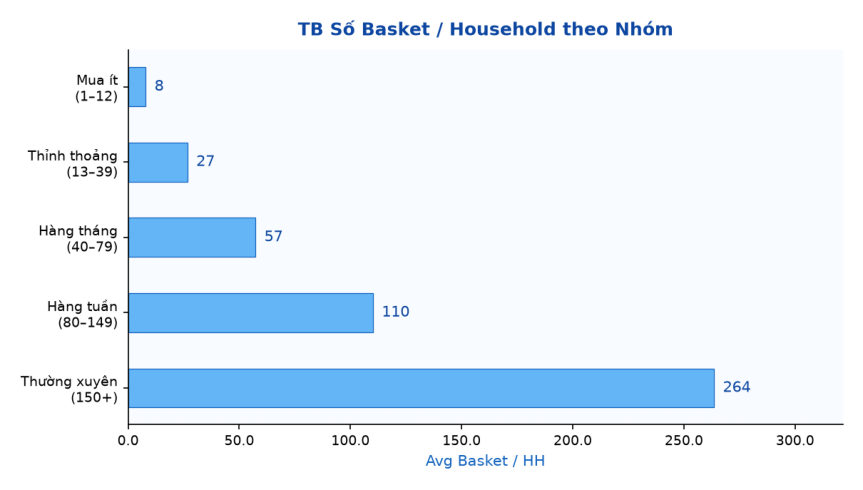

In [75]:
plot_baskets_per_hh(hh, CHARTS / 'chart3_baskets_per_hh.png')
show(CHARTS / 'chart3_baskets_per_hh.png')

## 5. TB Active Days / Household theo nhóm

  ✔  Saved: v:\Propensity_VSF\output\charts\chart4_active_days.png


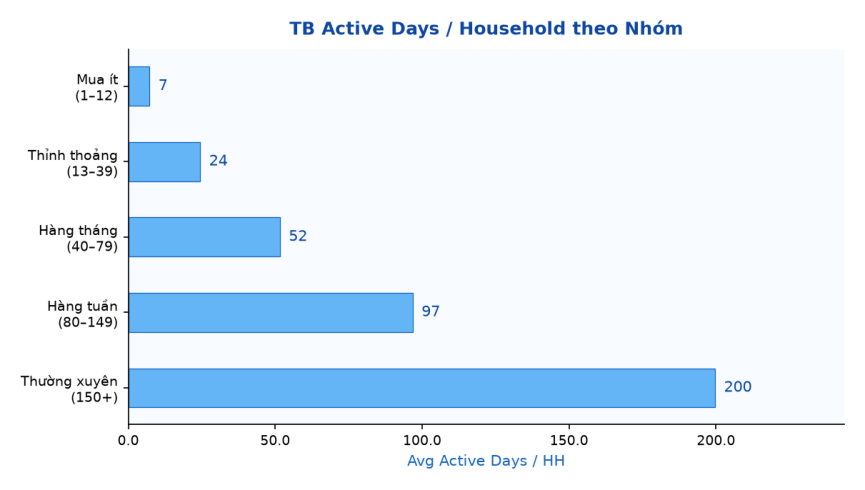

In [76]:
plot_active_days(hh, CHARTS / 'chart4_active_days.png')
show(CHARTS / 'chart4_active_days.png')

## 6. TB Lần Mua / Tuần theo nhóm

  ✔  Saved: v:\Propensity_VSF\output\charts\chart5_rate_weekly.png


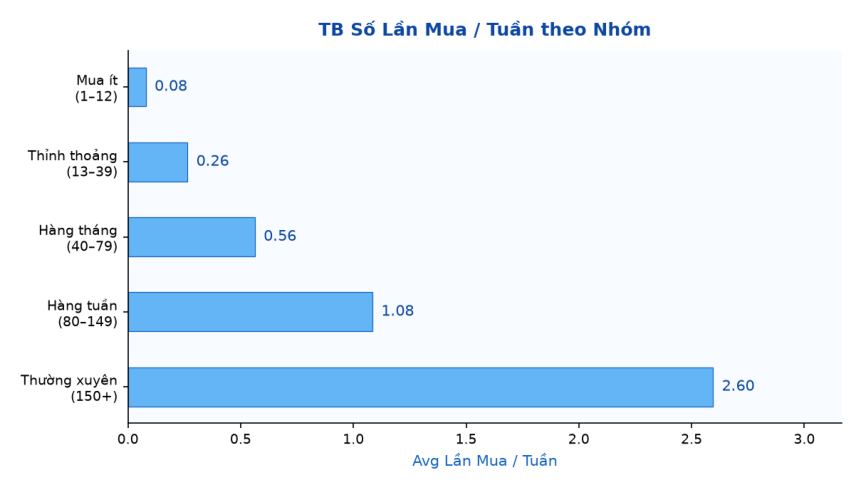

In [77]:
plot_purchase_rate_weekly(hh, CHARTS / 'chart5_rate_weekly.png')
show(CHARTS / 'chart5_rate_weekly.png')

## 7. TB Lần Mua / Tháng theo nhóm

  ✔  Saved: v:\Propensity_VSF\output\charts\chart6_rate_monthly.png


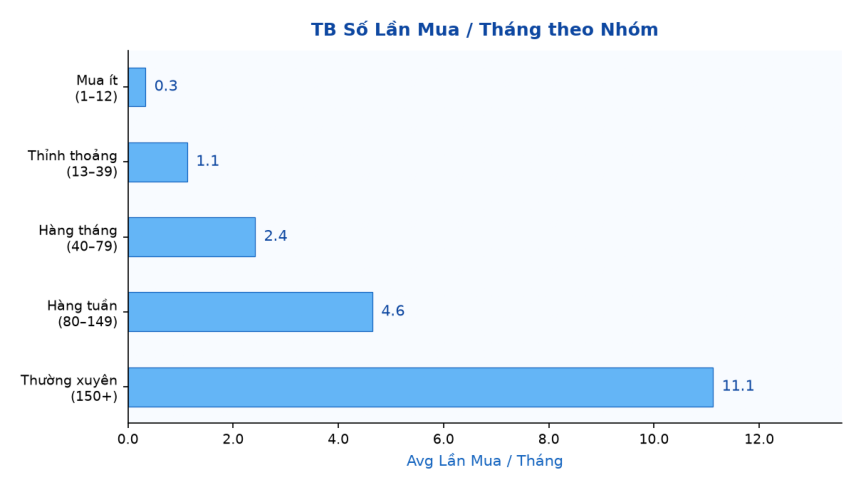

In [78]:
plot_purchase_rate_monthly(hh, CHARTS / 'chart6_rate_monthly.png')
show(CHARTS / 'chart6_rate_monthly.png')

## 8. Bảng tổng hợp

In [79]:
display(summary_table(hh))

,Nhóm,Số HH,TB Spending/HH ($),TB Basket/HH,TB Active Days,TB Lần/Tuần,TB Lần/Tháng,% HH,% Spending
0,Mua ít\n(1–12),152,242,8,7,0.08,0.3,6.1,0.5
1,Thỉnh thoảng\n(13–39),489,862,27,24,0.26,1.1,19.6,5.2
2,Hàng tháng\n(40–79),620,1886,57,52,0.56,2.4,24.8,14.5
3,Hàng tuần\n(80–149),651,3510,110,97,1.08,4.6,26.0,28.4
4,Thường xuyên\n(150+),588,7049,264,200,2.60,11.1,23.5,51.4


---

## 9. Nhận xét

| Nhóm | % HH | % Spending | TB Basket | TB Active Days | TB Lần/Tuần |
|------|------|------------|-----------|----------------|-------------|
| Mua ít (1–12) | 6% | 0.5% | 8 | 7 | 0.08 |
| Thỉnh thoảng (13–39) | 20% | 5% | 27 | 24 | 0.26 |
| Hàng tháng (40–79) | 25% | 15% | 57 | 52 | 0.56 |
| Hàng tuần (80–149) | 26% | 28% | 110 | 97 | 1.08 |
| Thường xuyên (150+) | 24% | 51% | 264 | 200 | 2.60 |

**Key insight**: Nhóm "Thường xuyên" chỉ 24% HH nhưng đóng góp 51% doanh thu — đây là nhóm cần ưu tiên trong Propensity Model.

---

# Phần B — Tổng quan Data

Trả lời 3 câu hỏi nền tảng về cấu trúc thời gian của dataset.

## Setup — load script tổng quan data

In [80]:
_spec2 = importlib.util.spec_from_file_location(
    'plot_data_overview', ROOT / 'scripts' / 'plot_data_overview.py'
)
_mod2 = importlib.util.module_from_spec(_spec2)
_spec2.loader.exec_module(_mod2)

load_temporal_data           = _mod2.load_temporal_data
plot_transactions_over_time  = _mod2.plot_transactions_over_time
plot_household_lifespan      = _mod2.plot_household_lifespan
plot_cohort_heatmap          = _mod2.plot_cohort_heatmap
plot_adoption_and_active_rate = _mod2.plot_adoption_and_active_rate

tx = load_temporal_data(DATA)
print(f'Rows: {len(tx):,} | DAY: {tx["DAY"].min()}–{tx["DAY"].max()} ({tx["DAY"].max()} ngày ~ {tx["DAY"].max()//30} tháng)')

Rows: 2,595,732 | DAY: 1–711 (711 ngày ~ 23 tháng)


## B1. Lượt Giao dịch theo Thời gian

> *Dataset dài bao nhiêu ngày/tháng? Có temporal gap lớn không?*

Đường xanh đậm = trung bình trượt 4 tuần. Vùng xanh nhạt = giá trị tuần thực tế.

  ✔  Saved: v:\Propensity_VSF\output\charts\chart_temporal_transactions.png


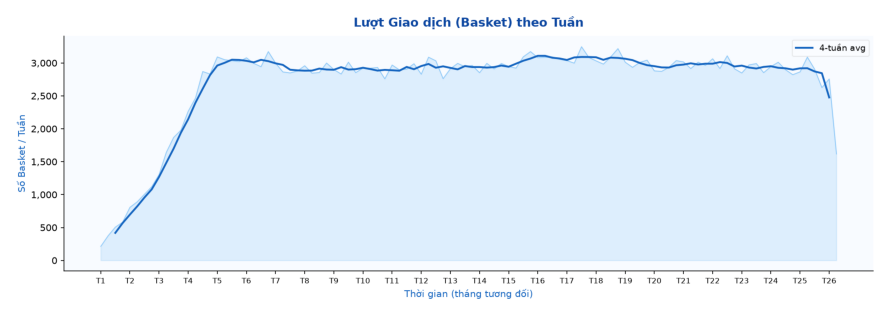

In [81]:
plot_transactions_over_time(tx, CHARTS / 'chart_temporal_transactions.png')
show(CHARTS / 'chart_temporal_transactions.png')

## B2. Phân phối Thời gian Hoạt động của Household (Activity Span)

> **Mục đích**: Trực quan hóa hình thái phân phối thời gian hoạt động của household (từ ngày mua đầu tiên đến ngày mua cuối cùng trong 2 năm).
> *Thời gian hoạt động = max(DAY) − min(DAY) + 1 (ngày)*.

  ✔  Saved: v:\Propensity_VSF\output\charts\chart_temporal_lifespan.png


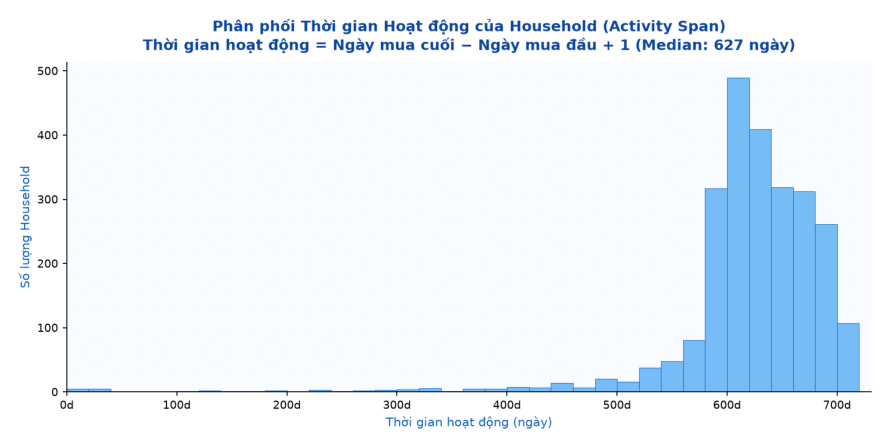

In [82]:
plot_household_lifespan(tx, CHARTS / 'chart_temporal_lifespan.png')
show(CHARTS / 'chart_temporal_lifespan.png')

## B3. Cohort Retention Heatmap

> *Phân bố thời gian hoạt động của các nhóm household cũ vs. mới?*

Mỗi hàng = cohort (nhóm gia nhập theo 2-tháng). Mỗi cột = offset kể từ lần mua đầu.  
Giá trị = % household trong cohort còn active ở period đó. Ô xám = period chưa xảy ra.

  ✔  Saved: v:\Propensity_VSF\output\charts\chart_temporal_cohort.png


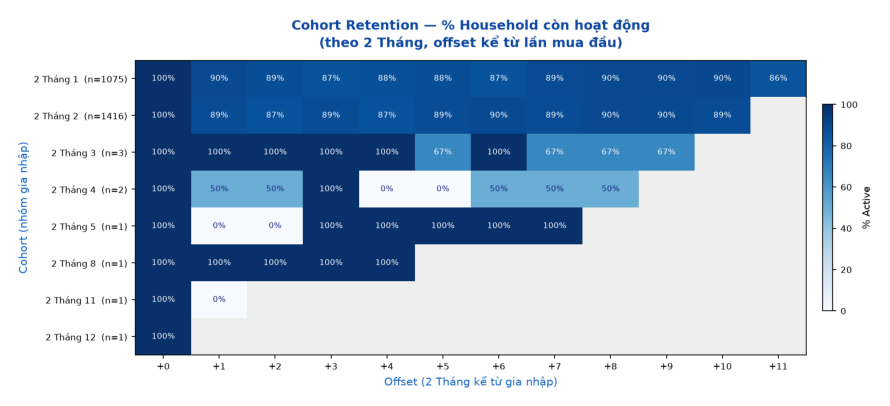

In [83]:
plot_cohort_heatmap(tx, CHARTS / 'chart_temporal_cohort.png', period='bimonth')
show(CHARTS / 'chart_temporal_cohort.png')

## B4. Tỷ lệ % Household Đã Mua & Còn Hoạt Động theo Thời Gian

> **Mục đích**: Theo dõi tiến trình gia nhập của tập khách hàng (Cumulative Adoption) và tỷ lệ khách hàng còn duy trì giao dịch (Active Rate trong 30 ngày qua) theo từng tuần/tháng.
- **Đường xanh đậm**: % Household đã phát sinh lần mua đầu tiên (tích lũy).
- **Đường xanh tươi + vùng tô**: % Household còn hoạt động (phát sinh giao dịch trong 30 ngày qua).
- **Đường nét đứt**: % Household chưa rời thị trường (First day <= t <= Last day).

  ✔  Saved: v:\Propensity_VSF\output\charts\chart_temporal_adoption_active.png


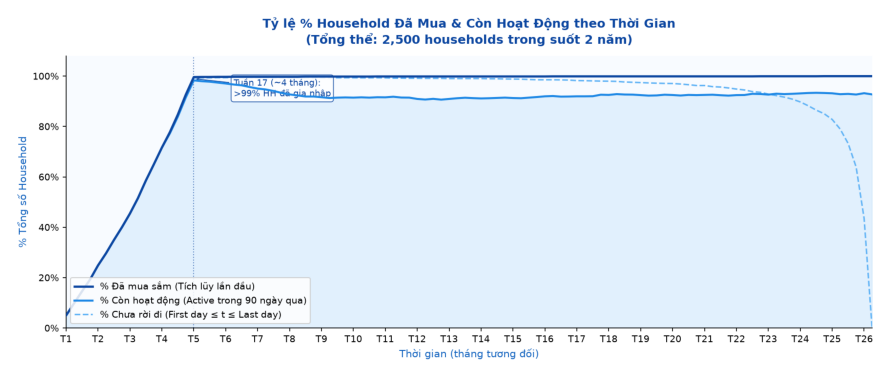

In [84]:
plot_adoption_and_active_rate(tx, CHARTS / 'chart_temporal_adoption_active.png')
show(CHARTS / 'chart_temporal_adoption_active.png')

## B5. Nhận xét tổng quan

| Câu hỏi | Phát hiện |
|---------|----------|
| **Dataset dài bao lâu?** | 711 ngày (~23.7 tháng, ~101 tuần), không có khoảng trống (temporal gap) lớn |
| **Tốc độ gia nhập (Adoption)?** | Tăng vọt trong 16 tuần đầu; đến **tuần 17 (~ngày 120) đã có >99% HH** phát sinh giao dịch đầu tiên |
| **Tỷ lệ còn hoạt động (Active Rate)?** | Duy trì cực kỳ ổn định ở mức **~80% – 82%** trong cửa sổ 30 ngày qua suốt 2 năm |
| **Thời gian hoạt động của HH?** | Phân phối lệch trái mạnh: Median hoạt động **627 ngày** (~21 tháng), hầu hết HH gắn bó dài hạn |
| **Cohort cũ vs. mới?** | Các cohort duy trì tỷ lệ active cao và ổn định, ít có hiện tượng churn tự nhiên đột ngột |

---

# Phần C — Phân tích Khoảng cách Mua & Tần suất Lặp lại (Interpurchase & Repeat Behavior)

Mục tiêu:
- Xác định tỷ lệ One-and-Done (1 lần) so với Repeaters (>= 2 lần).
- Phân tích phân phối khoảng cách giữa các lần mua (Interpurchase Interval) để nắm bắt chu kỳ mua sắm.
- Đánh giá tỷ lệ quay lại tích lũy (Cumulative Return Rate) để chọn khung thời gian dự báo (Horizon H).

## Setup — load script hành vi mua lại

In [85]:
_spec3 = importlib.util.spec_from_file_location(
    'plot_purchase_behavior', ROOT / 'scripts' / 'plot_purchase_behavior.py'
)
_mod3 = importlib.util.module_from_spec(_spec3)
_spec3.loader.exec_module(_mod3)

load_behavior_data           = _mod3.load_behavior_data
plot_one_and_done            = _mod3.plot_one_and_done
plot_interpurchase_histogram = _mod3.plot_interpurchase_histogram
plot_cumulative_return_rate  = _mod3.plot_cumulative_return_rate

hh_counts, intervals = load_behavior_data(DATA)
print(f'Total Households : {len(hh_counts):,}')
print(f'Total Intervals  : {len(intervals):,}')

Total Households : 2,500
Total Intervals  : 223,033


## C1. Sơ đồ 1: Biểu đồ Cột Ngang Gom Nhóm (Tỷ lệ >= 2 lần mua & Số Basket / Household)

> **Mục đích**: Thể hiện tỷ lệ phân bố số lượt mua của Household và làm nổi bật ranh giới giữa nhóm **One-and-done (1 lần)** và nhóm **Repeaters (>= 2 lần)**.

  ✔  Saved: v:\Propensity_VSF\output\charts\chart_behavior_oneshot.png


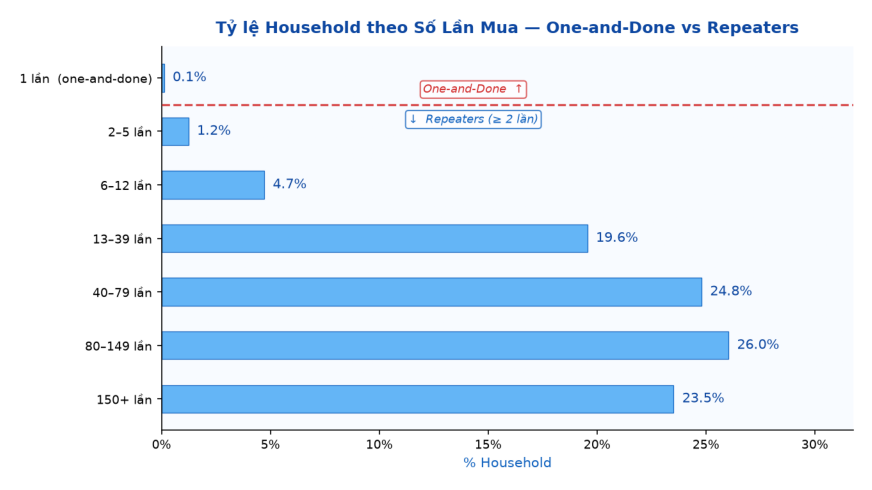

In [86]:
plot_one_and_done(hh_counts, CHARTS / 'chart_behavior_oneshot.png')
show(CHARTS / 'chart_behavior_oneshot.png')

## C2. Sơ đồ 2: Histogram Phân phối Khoảng cách Mua (Interpurchase Interval Distribution)

> **Mục đích**: Trực quan hóa hình thái phân phối số ngày giữa 2 lần mua liên tiếp (zoom cận cảnh <= 30 ngày, cột đầu xuất phát sát trục Y).

  ✔  Saved: v:\Propensity_VSF\output\charts\chart_behavior_intervals.png


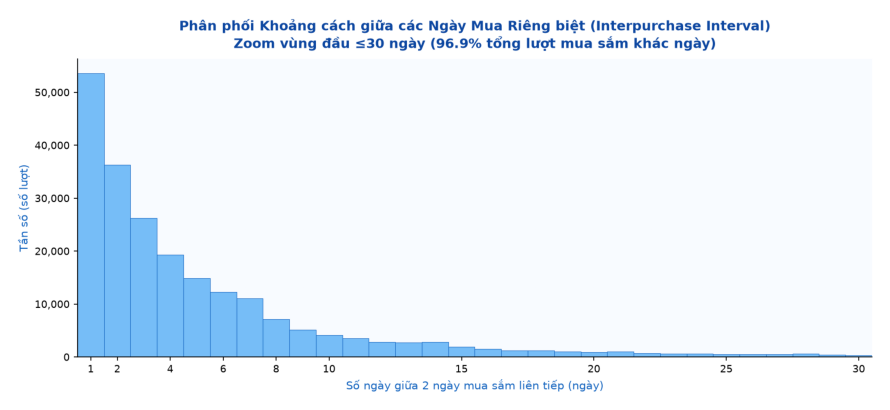

In [87]:
plot_interpurchase_histogram(intervals, CHARTS / 'chart_behavior_intervals.png')
show(CHARTS / 'chart_behavior_intervals.png')

## C3. Sơ đồ 3: Biểu đồ Đường Tích Lũy Độ Bao Phủ Nhãn (Cumulative Return Rate theo 7, 14, 30, 60, 90 ngày)

> **Mục đích**: Trả lời câu hỏi chọn $H$: Thể hiện tỷ lệ % lượt quay lại được cộng dồn tăng dần theo số ngày của Horizon $H$.

  ✔  Saved: v:\Propensity_VSF\output\charts\chart_behavior_return_rate.png


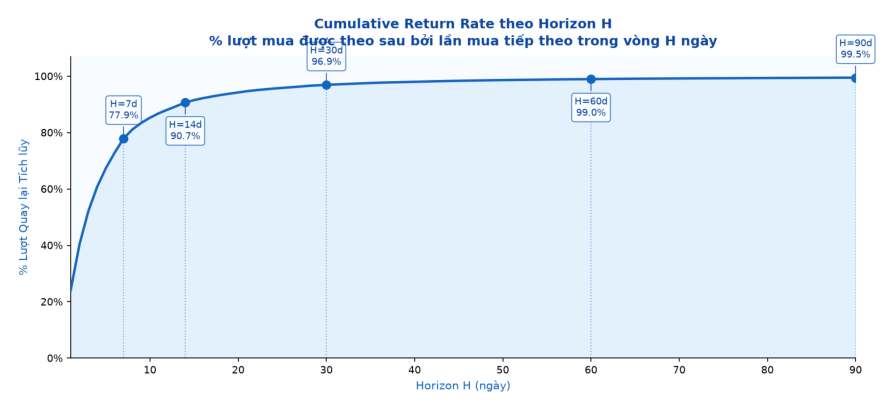

In [88]:
plot_cumulative_return_rate(intervals, CHARTS / 'chart_behavior_return_rate.png')
show(CHARTS / 'chart_behavior_return_rate.png')

## C4. Nhận xét & Đề xuất Horizon $H$ (Tính theo Ngày Mua Riêng Biệt)

| Chỉ số / Tiêu chí | Giá trị | Ý nghĩa thực tiễn |
|---|---|---|
| **One-and-Done** | < 0.2% (chỉ 3/2,500 HH) | Hầu như toàn bộ tập khách hàng là Repeaters, lịch sử mua sắm dày dặn |
| **Khoảng cách tối thiểu** | 1 ngày | Đã loại bỏ các giỏ hàng mua cùng ngày (gap = 0) để phản ánh đúng chu kỳ quay lại |
| **P25 / Median (P50)** | **2 ngày / 3 ngày** | 50% các lần khách quay lại cửa hàng diễn ra trong vòng 3 ngày |
| **P75 / P90 Gap** | **7 ngày / 14 ngày** | 90% các lần quay lại cửa hàng diễn ra trong vòng 2 tuần |
| **Horizon H = 7** | **77.9%** bao phủ | Bao phủ phần lớn thói quen mua sắm hàng tuần |
| **Horizon H = 14** | **90.7%** bao phủ | Khung 2 tuần bao phủ được 90% hành vi quay lại, là điểm cân bằng tối ưu cho Propensity Modeling |
| **Horizon H = 30** | **96.9%** bao phủ | Đạt mức bão hòa hành vi quay lại của khách hàng |